# Automatisk upptäckt av ärendetyper i kundklagomål

**Individuellt projekt – Statistisk programmering och ML (unsupervised learning)**

### Problemformulering
Företag får tusentals kundklagomål i fritext. För att kunna bemanna rätt, utbilda personal och sortera ärenden behöver man veta *vilka typer* av ärenden som kommer in. Men det finns sällan tid att läsa och märka upp texterna manuellt, och de färdiga kategorier som finns (t.ex. vilken produkt klagomålet gäller) säger inte vad kunden faktiskt har för problem.

**Affärsfråga:** Kan vi med unsupervised learning hitta naturliga ärendetyper i kunders klagomålstexter, utan manuell märkning, och identifiera vilka ärendetyper som oftare leder till att kunden får hjälp?

### Varför maskininlärning?
Med över 100 000 texter går det inte att läsa och kategorisera allt för hand. Det finns heller inget facit över vilka ärendetyper som finns. Därför används klustring: modellen grupperar texter som liknar varandra, och grupperna tolkas sedan i efterhand.

### Notebookens upplägg
1. Datakälla och inläsning
2. Urval och rensning
3. EDA av texterna *(kommande)*

## 1. Datakälla och inläsning

**Datakälla:** CFPB Consumer Complaint Database, den amerikanska konsumentskyddsmyndighetens öppna databas över klagomål på finansiella produkter och tjänster.

**Viktigt om datan:** den vanliga nedladdningen från CFPB innehåller inte längre klagomålstexterna. Texterna finns i stället i myndighetens [Narratives Archive](https://www.consumerfinance.gov/foia-requests/foia-electronic-reading-room/cfpb-consumer-complaint-database-narratives-archive/), som är uppdelat i zip-filer per tidsperiod.

Den senaste arkivfilen (augusti 2026) testades först, men innehöll bara **1 klagomål med text av 667 140**. Därför används en äldre period: **november 2022 – augusti 2023**.

Filen laddades ner 2026-11-02 och ligger i `data/`, som inte laddas upp till GitHub (för stor).

In [11]:
import pandas as pd

FIL = "../data/CCDB_Export_4_November_2022_through_August_2023.zip"

### 1.1 Hur många klagomål har text?

Konsumenten väljer själv om klagomålstexten får publiceras, så alla rader har inte text. Innan vi läser in allt kontrollerar vi hur stor andel som har text och om texterna är jämnt fördelade över perioden.

Filen läses i bitar om 200 000 rader, så att datorn inte får slut på minne.

In [12]:
totalt = 0
med_text = 0
datum = []

for chunk in pd.read_csv(FIL, usecols=["Date received", "Consumer complaint narrative"],
                         chunksize=200_000, low_memory=False):
    totalt += len(chunk)
    har_text = chunk["Consumer complaint narrative"].notna()
    med_text += har_text.sum()
    datum.append(pd.to_datetime(chunk.loc[har_text, "Date received"]))

datum = pd.concat(datum)
print("Totalt antal rader:", totalt)
print("Med text:", med_text, f"({med_text / totalt:.1%})")
print("Texter finns från", datum.min().date(), "till", datum.max().date())
print("\nAntal texter per månad:")
print(datum.dt.to_period("M").value_counts().sort_index())

Totalt antal rader: 987495
Med text: 388495 (39.3%)
Texter finns från 2022-11-01 till 2023-08-31

Antal texter per månad:
Date received
2022-11    31533
2022-12    35163
2023-01    39586
2023-02    35023
2023-03    41060
2023-04    36594
2023-05    41134
2023-06    41320
2023-07    40771
2023-08    46311
Freq: M, Name: count, dtype: int64


**Resultat:** 388 495 av 987 495 klagomål (39,3 %) har text. Texterna är jämnt fördelade över alla tio månader (ca 31 000–46 000 per månad), utan luckor. En arkivfil räcker därför för projektet.

**Begränsning:** eftersom konsumenterna själva väljer att publicera sin text kan de skilja sig från dem som inte gör det (urvalsproblem).

### 1.2 Läs in klagomålen med text

Bara de kolumner som behövs läses in:

| Kolumn | Används till |
|---|---|
| `Consumer complaint narrative` | Själva texten som ska klustras |
| `Product`, `Sub-product`, `Issue`, `Sub-issue` | Konsumentens egen kategorisering, används för att jämföra med klustren |
| `Company response to consumer` | Utfall: fick kunden hjälp? |
| `Date received`, `Company`, `State`, `Submitted via` | Beskriva och tolka klustren |
| `Timely response?` | Om företaget svarade i tid |
| `Complaint ID` | Unikt id |

Resultatet sparas som en parquet-fil, ett komprimerat format som går mycket snabbare att läsa in nästa gång.

In [13]:
cols = [
    "Date received", "Product", "Sub-product", "Issue", "Sub-issue",
    "Consumer complaint narrative", "Company", "State",
    "Submitted via", "Company response to consumer",
    "Timely response?", "Complaint ID",
]

chunks = []
for chunk in pd.read_csv(FIL, usecols=cols, chunksize=200_000, low_memory=False):
    chunks.append(chunk.dropna(subset=["Consumer complaint narrative"]))

df = pd.concat(chunks, ignore_index=True)
df["Date received"] = pd.to_datetime(df["Date received"])

df.to_parquet("../data/complaints_narratives.parquet")

print("Antal klagomål:", len(df))
print("\nAndel per produkt:")
print(df["Product"].value_counts(normalize=True).round(3))
print("\nTimely response?:\n", df["Timely response?"].value_counts(normalize=True).round(3))
print("\nCompany response:\n", df["Company response to consumer"].value_counts())

Antal klagomål: 388495

Andel per produkt:
Product
Credit reporting, credit repair services, or other personal consumer reports    0.704
Debt collection                                                                 0.073
Credit card or prepaid card                                                     0.065
Checking or savings account                                                     0.059
Mortgage                                                                        0.028
Credit reporting or other personal consumer reports                             0.018
Money transfer, virtual currency, or money service                              0.018
Vehicle loan or lease                                                           0.016
Payday loan, title loan, or personal loan                                       0.009
Student loan                                                                    0.008
Credit card                                                                     0.002
Pay

**Tre observationer som styr rensningen:**

1. **Kreditupplysningar dominerar.** De två kategorierna som börjar med "Credit reporting" står tillsammans för ca 72 % av klagomålen. De skulle dominera klustringen och dölja övriga ärendetyper.
2. **`Timely response?` har nästan ingen variation.** 99,4 % fick svar i tid, så kolumnen kan inte skilja ärendetyper åt. I stället används `Company response to consumer` som utfall.
3. **Produktnamnen är inte enhetliga.** CFPB har bytt namn på kategorier över tid, t.ex. finns både "Credit card" och "Credit card or prepaid card".

## 2. Urval och rensning

### 2.1 Ta bort kreditupplysningar och slå ihop produktnamn

**Kreditupplysningar tas bort** eftersom de handlar nästan uteslutande om tvister med tre kreditbyråer och har en annan karaktär än vanliga kundserviceärenden. Kvar blir klagomål om bankkonton, kort, inkasso, lån och betalningar.

**Produktnamn som betyder samma sak slås ihop** så att samma produkt inte räknas som två kategorier.

Vi räknar också hur många texter som är exakta dubbletter (samma text inskickad flera gånger).

In [14]:
df = pd.read_parquet("../data/complaints_narratives.parquet")

# Ta bort kreditupplysningar (båda namnvarianterna)
df = df[~df["Product"].str.startswith("Credit reporting")]

# Slå ihop produktnamn som bytt namn över tid
produkt_map = {
    "Credit card": "Credit card or prepaid card",
    "Prepaid card": "Credit card or prepaid card",
    "Payday loan, title loan, personal loan, or advance loan":
        "Payday loan, title loan, or personal loan",
}
df["Product"] = df["Product"].replace(produkt_map)

# Räkna dubbletter
dubbletter = df.duplicated(subset="Consumer complaint narrative").sum()

print("Antal klagomål kvar:", len(df))
print("Exakta dubbletter av text:", dubbletter, f"({dubbletter / len(df):.1%})")
print("\nAntal per produkt:")
print(df["Product"].value_counts())
print("\nCompany response:")
print(df["Company response to consumer"].value_counts())

df.to_parquet("../data/complaints_filtered.parquet")

Antal klagomål kvar: 107916
Exakta dubbletter av text: 5416 (5.0%)

Antal per produkt:
Product
Debt collection                                       28502
Credit card or prepaid card                           26174
Checking or savings account                           22964
Mortgage                                              10832
Money transfer, virtual currency, or money service     6923
Vehicle loan or lease                                  6112
Payday loan, title loan, or personal loan              3446
Student loan                                           2941
Debt or credit management                                22
Name: count, dtype: int64

Company response:
Company response to consumer
Closed with explanation            87428
Closed with non-monetary relief    11107
Closed with monetary relief         9146
Untimely response                    235
Name: count, dtype: int64


**Resultat:** 107 916 klagomål kvar, fördelade på åtta produkter med rimlig balans (störst är inkasso med ca 28 500, minst studielån med ca 2 900). 5,0 % av texterna är exakta dubbletter, troligen mallbrev.

### 2.2 Slutlig rensning och utfallsvariabel

| Åtgärd | Motivering |
|---|---|
| Ta bort exakta dubbletter (behåll första) | Identiska texter skulle bilda konstgjorda, extremt täta kluster och ge en missvisande bild av vad kunderna klagar på. |
| Ta bort "Debt or credit management" | Endast 22 klagomål, för få för att säga något om. |
| Ta bort "Untimely response" | 235 klagomål saknar besked om hur ärendet avslutades. |

**Utfallsvariabel `fick_hjalp`:**
- `1` = företaget gav kunden ekonomisk kompensation (*monetary relief*) eller annan hjälp (*non-monetary relief*)
- `0` = ärendet avslutades bara med en förklaring

Variabeln används **inte** i klustringen. Den används i efterhand för att undersöka om vissa ärendetyper oftare leder till att kunden får rätt.

In [15]:
df = pd.read_parquet("../data/complaints_filtered.parquet")

df = df.drop_duplicates(subset="Consumer complaint narrative", keep="first")
df = df[df["Product"] != "Debt or credit management"]
df = df[df["Company response to consumer"] != "Untimely response"]

df["fick_hjalp"] = df["Company response to consumer"].isin(
    ["Closed with monetary relief", "Closed with non-monetary relief"]
).astype(int)

print("Antal klagomål:", len(df))
print("Andel som fick hjälp:", df["fick_hjalp"].mean().round(3))
print("\nAndel som fick hjälp per produkt:")
print(df.groupby("Product")["fick_hjalp"].mean().sort_values(ascending=False).round(3))

df.to_parquet("../data/complaints_clean.parquet")

Antal klagomål: 102247
Andel som fick hjälp: 0.175

Andel som fick hjälp per produkt:
Product
Credit card or prepaid card                           0.324
Checking or savings account                           0.200
Money transfer, virtual currency, or money service    0.131
Student loan                                          0.129
Debt collection                                       0.127
Payday loan, title loan, or personal loan             0.091
Vehicle loan or lease                                 0.072
Mortgage                                              0.050
Name: fick_hjalp, dtype: float64


**Resultat:** 102 247 klagomål återstår, och 17,5 % av kunderna fick någon form av hjälp.

**Första insikt:** chansen att få hjälp skiljer sig kraftigt mellan produkter. Klagomål om kort leder till hjälp i 32 % av fallen, bolån bara i 5 %. Samma fråga ställs senare om klustren: skiljer sig ärendetyperna mer än produkterna gör?

> **Statistisk anmärkning:** med över 100 000 rader blir nästan varje skillnad statistiskt signifikant. När chi²-test görs redovisas därför också effektstorleken (Cramér's V), som visar hur *starkt* sambandet är.

### Sammanfattning av urvalet

| Steg | Antal klagomål |
|---|---|
| Arkivfil nov 2022 – aug 2023 | 987 495 |
| Med klagomålstext | 388 495 |
| Utan kreditupplysningar | 107 916 |
| Efter borttagning av dubbletter, "Debt or credit management" och "Untimely response" | 102 247 |

Den rensade datan sparas i `data/complaints_clean.parquet` och är utgångspunkten för EDA och modellering.

## 3. EDA av klagomålstexterna

### 3.1 Textlängd

Hur långa texterna är påverkar klustringen. Mycket korta texter innehåller för lite information för att kunna grupperas, och mycket långa texter kan få för stor vikt. Vi undersöker:

- fördelningen av antal ord per klagomål
- om längden skiljer sig mellan produkter
- hur vanlig CFPB:s maskering av personuppgifter ("XXXX") är
- om kunder som fick hjälp skrev längre eller kortare texter än de som inte fick det

Antal ord per klagomål:
count    102247.0
mean        215.0
std         252.0
min           1.0
25%          77.0
50%         149.0
75%         266.0
max        5947.0
Name: antal_ord, dtype: float64

Texter med färre än 10 ord: 874
Andel texter med maskering (XXXX): 0.844


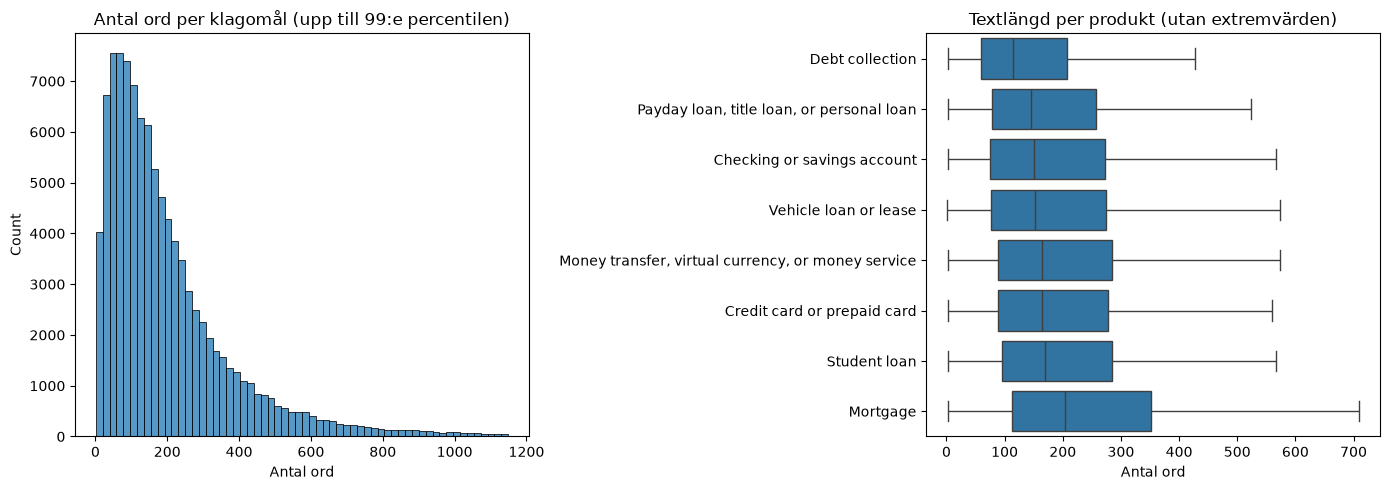


Median antal ord – fick hjälp: 163.0
Median antal ord – fick inte hjälp: 146.0
Mann-Whitney U, p-värde: 2.883624691151515e-40


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

df = pd.read_parquet("../data/complaints_clean.parquet")
text = df["Consumer complaint narrative"]

df["antal_ord"] = text.str.split().str.len()
df["antal_xxxx"] = text.str.count(r"X{2,}")

print("Antal ord per klagomål:")
print(df["antal_ord"].describe().round(0))
print("\nTexter med färre än 10 ord:", (df["antal_ord"] < 10).sum())
print("Andel texter med maskering (XXXX):", (df["antal_xxxx"] > 0).mean().round(3))

# Histogram (klipps vid 99:e percentilen så att extremvärden inte trycker ihop grafen)
grans = df["antal_ord"].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df.loc[df["antal_ord"] <= grans, "antal_ord"], bins=60, ax=axes[0])
axes[0].set_title("Antal ord per klagomål (upp till 99:e percentilen)")
axes[0].set_xlabel("Antal ord")

ordning = df.groupby("Product")["antal_ord"].median().sort_values().index
sns.boxplot(data=df, y="Product", x="antal_ord", order=ordning,
            showfliers=False, ax=axes[1])
axes[1].set_title("Textlängd per produkt (utan extremvärden)")
axes[1].set_xlabel("Antal ord")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Statistiskt test: skriver de som fick hjälp längre texter?
hjalp = df.loc[df["fick_hjalp"] == 1, "antal_ord"]
ingen = df.loc[df["fick_hjalp"] == 0, "antal_ord"]
stat, p = mannwhitneyu(hjalp, ingen)

print("\nMedian antal ord – fick hjälp:", hjalp.median())
print("Median antal ord – fick inte hjälp:", ingen.median())
print("Mann-Whitney U, p-värde:", p)

In [17]:
# Effektstorlek: rank-biserial korrelation (-1 till 1, nära 0 = ingen praktisk skillnad)
r = 1 - (2 * stat) / (len(hjalp) * len(ingen))
print("Effektstorlek (rank-biserial r):", round(r, 3))

Effektstorlek (rank-biserial r): -0.063


**Resultat – textlängd:**

- Texterna är i median 149 ord långa, men fördelningen är kraftigt högerskev: de flesta är 77–266 ord, medan några är nästan 6 000 ord.
- Bolåneklagomål är längst (median ca 200 ord) och inkassoklagomål kortast (median ca 115 ord). Det är rimligt eftersom bolåneärenden ofta gäller långa förlopp med många inblandade parter.
- 84 % av texterna innehåller CFPB:s maskering av personuppgifter ("XXXX"). Den tas bort i textrensningen, annars blir den det vanligaste "ordet" i varje kluster.

**Statistiskt test: skriver kunder som får hjälp längre texter?**

Mann-Whitney U användes i stället för t-test eftersom textlängderna inte är normalfördelade (kraftigt skeva) och testet jämför rangordning i stället för medelvärden, som påverkas av extremvärden.

- Median: 163 ord (fick hjälp) mot 146 ord (fick inte hjälp)
- p-värde < 0,001, alltså statistiskt signifikant
- Effektstorlek (rank-biserial r): −0,063, alltså en mycket svag effekt (|r| < 0,1)

**Slutsats:** skillnaden är statistiskt säker men praktiskt liten. Med över 100 000 observationer blir även små skillnader signifikanta, och textlängden i sig förklarar knappt om kunden får hjälp. Det tyder på att det är *innehållet* i klagomålet som spelar roll, vilket är det klustringen ska undersöka.

**Beslut:** texter med färre än 10 ord (874 st, 0,9 %) tas bort eftersom de innehåller för lite information för att kunna klustras. Långa texter behålls eftersom TF-IDF normaliserar varje text.

### 3.2 Volym över tid

Vi undersöker hur antalet klagomål per produkt och andelen som fick hjälp utvecklas per månad. Syftet är att se om perioden är stabil, eller om det finns toppar som kan förklaras av händelser och som senare kan synas i enskilda kluster.

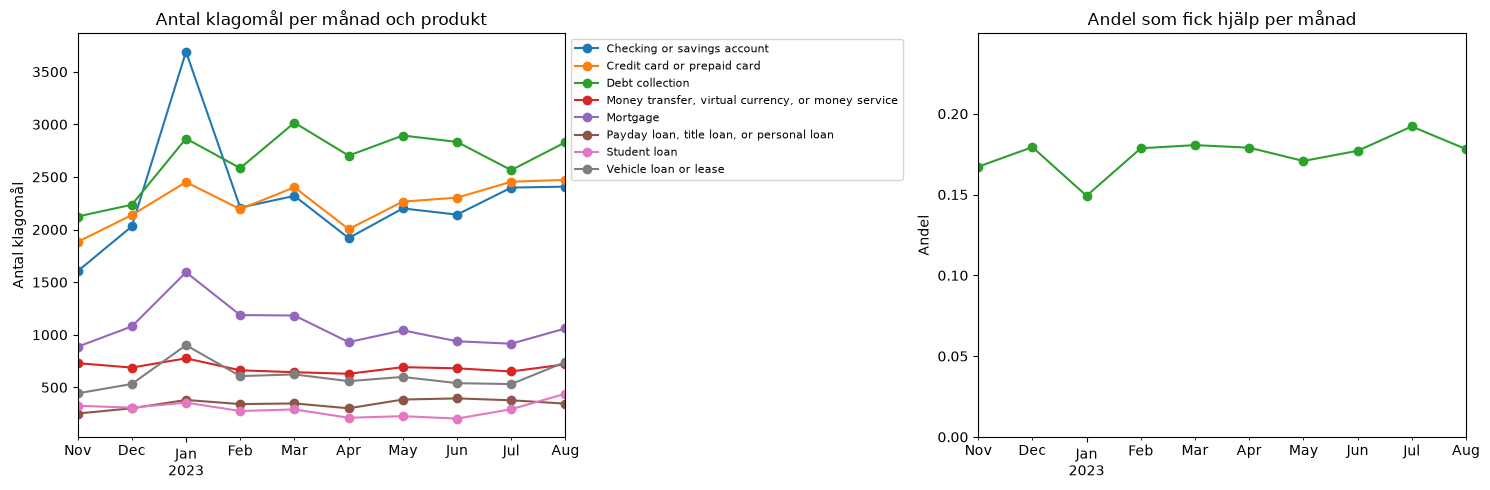

manad
2022-11-01     8245
2022-12-01     9311
2023-01-01    13013
2023-02-01    10059
2023-03-01    10825
2023-04-01     9256
2023-05-01    10304
2023-06-01    10035
2023-07-01    10185
2023-08-01    11014
Name: Totalt per månad, dtype: int64

Andel som fick hjälp per månad:
manad
2022-11-01    0.167
2022-12-01    0.179
2023-01-01    0.149
2023-02-01    0.179
2023-03-01    0.181
2023-04-01    0.179
2023-05-01    0.171
2023-06-01    0.177
2023-07-01    0.192
2023-08-01    0.178
Name: fick_hjalp, dtype: float64


In [18]:
df["manad"] = df["Date received"].dt.to_period("M").dt.to_timestamp()

per_manad = df.groupby(["manad", "Product"]).size().unstack()
hjalp_manad = df.groupby("manad")["fick_hjalp"].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

per_manad.plot(ax=axes[0], marker="o")
axes[0].set_title("Antal klagomål per månad och produkt")
axes[0].set_xlabel("")
axes[0].set_ylabel("Antal klagomål")
axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))

hjalp_manad.plot(ax=axes[1], marker="o", color="tab:green")
axes[1].set_title("Andel som fick hjälp per månad")
axes[1].set_xlabel("")
axes[1].set_ylabel("Andel")
axes[1].set_ylim(0, hjalp_manad.max() * 1.3)

plt.tight_layout()
plt.show()

print(per_manad.sum(axis=1).rename("Totalt per månad"))
print("\nAndel som fick hjälp per månad:")
print(hjalp_manad.round(3))

In [19]:
bank = df[df["Product"] == "Checking or savings account"]
jan = bank[bank["manad"] == "2023-01-01"]
ovriga = bank[bank["manad"] != "2023-01-01"]

jamforelse = pd.DataFrame({
    "januari": jan["Company"].value_counts(),
    "snitt_ovriga_manader": (ovriga["Company"].value_counts() / 9).round(0),
}).fillna(0)
jamforelse["okning"] = jamforelse["januari"] - jamforelse["snitt_ovriga_manader"]

print(jamforelse.sort_values("okning", ascending=False).head(10))

                                       januari  snitt_ovriga_manader  okning
Company                                                                     
WELLS FARGO & COMPANY                   1961.0                 340.0  1621.0
CITIBANK, N.A.                           130.0                 115.0    15.0
BANK OF THE WEST                          15.0                   3.0    12.0
BANK OF AMERICA, NATIONAL ASSOCIATION    293.0                 287.0     6.0
Paypal Holdings, Inc                      28.0                  22.0     6.0
TRUIST FINANCIAL CORPORATION              68.0                  63.0     5.0
FIRST HORIZON BANK                         7.0                   2.0     5.0
AMERICAN EXPRESS COMPANY                  16.0                  11.0     5.0
MORGAN STANLEY & CO. LLC                   6.0                   2.0     4.0
FinCo Services Inc DBA Current            14.0                  10.0     4.0


**Resultat – volym över tid:**

- Antalet klagomål är relativt stabilt, ca 9 000–11 000 per månad, med en svag uppåtgående trend.
- **Januari 2023 sticker ut** med 13 013 klagomål. Ökningen drivs främst av bankkonton (ca 3 700 mot normalt ca 2 100), men även bolån och billån ökar.
- Andelen som fick hjälp ligger stabilt kring 17–19 %, utom i januari då den sjunker till 14,9 %. Toppen i januari bestod alltså av klagomål som i lägre grad ledde till kompensation.
- **Förklaring av januaritoppen:** ökningen för bankkonton drivs nästan helt av ett enda företag, Wells Fargo (1 961 klagomål i januari mot i snitt ca 340 övriga månader). Det sammanfaller i tid med att CFPB den 20 december 2022 beordrade Wells Fargo att betala 3,7 miljarder dollar för misskötsel av bankkonton, billån och bolån, samma tre produkter som ökar i januari. Sambandet i tid tyder på en koppling, men datan i sig visar inte orsaken.

**Betydelse för projektet:** perioden är i övrigt stabil, vilket gör den lämplig för klustring. Januaritoppen är intressant att följa upp: om klustringen fungerar bör toppen synas tydligt i ett eller ett fåtal specifika kluster.